# Fatigue-Adaptive Classification Using Open Surface EMG Datasets

**A reproducible, participant-independent machine-learning and deep-learning study**

**Research question.** How accurately can subjective muscular fatigue levels be classified from multichannel surface electromyography (sEMG) recordings under unseen-participant evaluation, and how does labeled subject-specific calibration affect subsequent classification performance?

**Source.** [Public dataset, Zenodo record 14182446](https://zenodo.org/records/14182446); 13 participant archives, 12 trial pairs per subject where available, four simultaneously recorded EMG channels per trial, and time-stamped self-perceived fatigue ratings. Fatigue levels are ordinal categories (0–2), **not** independently validated medical diagnoses.

**Study design.** Record-level quality control; physiological filtering; 1-second overlapping windows; 44 channel-specific hand-engineered descriptors; classical baselines with participant-grouped inner hyperparameter optimization; participant-held-out (LOSO) evaluation of both traditional classifiers and convolutional neural networks; chronological supervised calibration; feature-domain ablations; subject-level uncertainty; reproducibility and export artifacts.

All experiment settings, exclusions, class distributions, timing, hyperparameters and limitations are saved. No numerical performance is reported without execution on actual signals. This is an **offline** study; zero-phase preprocessing is not causal real-time processing.

## 1. Reproducible computational environment

The entire study executes in one Google Colab notebook. The workspace is local to the Colab runtime; **Google Drive authentication is not required**. Data are downloaded from the public archival source only if the files are absent or do not match the published sizes. Temporary runtime files disappear when the session is reset; save the exported experiment package when execution completes. Colab GPU acceleration is strongly recommended for neural-network experiments.

In [ ]:
from pathlib import Path
import os, sys, json, time, random, warnings, platform, shutil
import numpy as np

ROOT = Path('/content/EMG_Fatigue_Workspace')
RAW = ROOT / 'data' / 'raw'
OUT = ROOT / 'results' / 'ONE_NOTEBOOK_RESEARCH'
CACHE = ROOT / 'cache' / 'ONE_NOTEBOOK_RESEARCH'
for p in [RAW, OUT, CACHE]: p.mkdir(parents=True, exist_ok=True)
SEED = 42
FAST_DEMO = False  # Leave False for the full subject evaluation
MAX_WINDOWS_PER_SUBJECT = 900 if not FAST_DEMO else 45
MAX_WINDOWS_PER_TRIAL = 150 if not FAST_DEMO else 20
WINDOW_SECONDS = 1.0
HOP_SECONDS = 0.5
PURITY_THRESHOLD = 0.80
TARGET_FS_HZ = 1259.0
FILTER_LOW_HZ = 20.0
FILTER_HIGH_HZ = 450.0
SUPPORT_FRACTION = 0.20
GAP_SECONDS = 2.0
CNN_ENABLED = True  # Full participant-held-out evaluation
random.seed(SEED); np.random.seed(SEED)
usage = shutil.disk_usage('/content')
print(f'Colab available disk: {usage.free/1e9:.1f} GB')
if usage.free < 9_000_000_000:
    raise RuntimeError('Insufficient Colab disk space (<9 GB free). Free runtime storage or use a larger runtime.')
print('Research output:', OUT, '\nRaw data:', RAW)

CNN_EPOCHS = 18 if not FAST_DEMO else 2
CNN_PATIENCE = 5
CNN_BATCH_SIZE = 128
MIN_VALID_SUBJECTS = 10 if not FAST_DEMO else 4

Colab available disk: 93.6 GB
Research output: /content/EMG_Fatigue_Workspace/results/ONE_NOTEBOOK_RESEARCH 
Raw data: /content/EMG_Fatigue_Workspace/data/raw


## 2. Dependencies and environment fingerprint

Install constrained numerical packages and record all installed versions for experimental reproducibility. Scikit-learn preprocessing occurs inside each training fold; neither imputation nor feature scaling is fitted globally.

In [ ]:
%pip -q install -U "scikit-learn>=1.4,<2.0" "pandas>=2.1,<3.0" "scipy>=1.11,<2.0" matplotlib seaborn tqdm requests joblib pyarrow openpyxl tabulate
import pandas as pd, scipy, sklearn, matplotlib, requests, joblib
from scipy import signal
from scipy.stats import wilcoxon
from tqdm.auto import tqdm
from zipfile import ZipFile, BadZipFile
from io import TextIOWrapper
from collections import Counter, defaultdict
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, GridSearchCV
from sklearn.metrics import (confusion_matrix, classification_report, f1_score,
    precision_score, recall_score, accuracy_score, balanced_accuracy_score)
import matplotlib.pyplot as plt
VERSIONS={k: getattr(sys.modules[k], '__version__', 'unknown') for k in ['numpy','pandas','scipy','sklearn','matplotlib']}
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'versions':VERSIONS,'seed':SEED}, indent=2))
print(VERSIONS)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 10.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently t

## 3. Official dataset acquisition and integrity verification

The Zenodo REST metadata provides file locations, sizes and checksums. Downloaded archives are streamed into temporary files, checked, and then atomically renamed. Reusing matching files avoids unnecessary network transfer; direct Colab execution does not require Drive. A network error stops the experiment rather than silently substituting synthetic signals.

In [ ]:
import hashlib
ZENODO_RECORD = 14182446

def find_main_archives(root):
    allz=list(root.rglob('*.zip'))
    emg=[p for p in allz if p.name.lower()=='semg_data.zip']
    fat=[p for p in allz if p.name.lower()=='self_perceived_fatigue_index.zip']
    return (emg[0] if emg else None), (fat[0] if fat else None)

def zenodo_fetch_missing():
    r=requests.get(f'https://zenodo.org/api/records/{ZENODO_RECORD}',timeout=75)
    r.raise_for_status(); entries=r.json()['files']
    needed={'semg_data.zip','self_perceived_fatigue_index.zip'}
    for entry in entries:
        name=Path(entry['key']).name
        if name.lower() not in needed: continue
        target=RAW/name; size=entry['size']
        if target.exists() and target.stat().st_size==size:
            print('Already downloaded:', target); continue
        url=entry['links'].get('self') or entry['links'].get('content')
        partial=Path(str(target)+'.part')
        with requests.get(url,stream=True,timeout=(35,150)) as response:
            response.raise_for_status()
            from tqdm.auto import tqdm as tq
            with open(partial,'wb') as f, tq(total=size,unit='B',unit_scale=True,desc=name) as bar:
                for chunk in response.iter_content(2**20):
                    if chunk: f.write(chunk);bar.update(len(chunk))
        if partial.stat().st_size != size: raise RuntimeError(f'Incomplete download: {name}')
        ch=entry.get('checksum','')
        if ':' in ch:
            algorithm,expected=ch.split(':',1)
            if algorithm in hashlib.algorithms_available:
                h=hashlib.new(algorithm)
                with open(partial,'rb') as f:
                    for chunk in iter(lambda:f.read(4*2**20), b''): h.update(chunk)
                if h.hexdigest().lower()!=expected.lower(): raise RuntimeError('Checksum failed '+name)
        partial.replace(target)
    return find_main_archives(RAW)

EMG_MAIN,FATIGUE_MAIN=find_main_archives(RAW)
if EMG_MAIN is None or FATIGUE_MAIN is None:
    print('Missing archives; downloading from the official Zenodo record ...')
    EMG_MAIN,FATIGUE_MAIN=zenodo_fetch_missing()
assert EMG_MAIN and FATIGUE_MAIN, 'Archives still absent. Check Colab disk and Zenodo access.'
print('EMG:', EMG_MAIN, 'Fatigue:', FATIGUE_MAIN)

Missing archives; downloading from the official Zenodo record ...


self_perceived_fatigue_index.zip:   0%|          | 0.00/5.14M [00:00<?, ?B/s]

sEMG_data.zip:   0%|          | 0.00/3.30G [00:00<?, ?B/s]

EMG: /content/EMG_Fatigue_Workspace/data/raw/sEMG_data.zip Fatigue: /content/EMG_Fatigue_Workspace/data/raw/self_perceived_fatigue_index.zip


## 4. Nested ZIP indexing and subject/trial manifest

Each master archive contains individual `subject_N.zip` files. Trial pairs are matched on participant and trial number, retaining the original subject partition. Maximum voluntary contraction (MVC) signals are excluded from fatigue classification because they do not have the corresponding fatigue-trial labels; they remain a documented optional calibration resource.

In [ ]:
import re, shutil

def unzip_subject_archives(main, kind):
    folder=RAW/('emg_subject_archives' if kind=='emg' else 'fatigue_subject_archives')
    folder.mkdir(exist_ok=True,parents=True)
    with ZipFile(main) as z:
        for member in z.infolist():
            if not re.search(r'subject_\d+\.zip$',member.filename,re.I): continue
            target=folder/Path(member.filename).name
            if target.exists() and target.stat().st_size==member.file_size: continue
            tmp=Path(str(target)+'.part')
            with z.open(member) as src, open(tmp,'wb') as dst: shutil.copyfileobj(src,dst,1024*1024)
            tmp.replace(target)
    return {int(re.search(r'subject_(\d+)',p.name,re.I).group(1)):p for p in folder.glob('subject_*.zip')}

EMG_ZIPS=unzip_subject_archives(EMG_MAIN,'emg')
FAT_ZIPS=unzip_subject_archives(FATIGUE_MAIN,'fatigue')
assert len(set(EMG_ZIPS)&set(FAT_ZIPS))>=MIN_VALID_SUBJECTS, 'Insufficient matched participants.'
records=[]
for subject in sorted(set(EMG_ZIPS)&set(FAT_ZIPS)):
    with ZipFile(EMG_ZIPS[subject]) as em, ZipFile(FAT_ZIPS[subject]) as fa:
        e={int(m.group(1)):name for name in em.namelist() if (m:=re.search(r'/trial_(\d+)\.csv$',name,re.I))}
        f={int(m.group(1)):name for name in fa.namelist() if (m:=re.search(r'/trial_(\d+)\.csv$',name,re.I))}
        for trial in sorted(set(e)&set(f)):
            records.append(dict(subject=subject,trial=trial,emg_archive=str(EMG_ZIPS[subject]),fatigue_archive=str(FAT_ZIPS[subject]),emg_member=e[trial],fatigue_member=f[trial]))
MANIFEST=pd.DataFrame(records)
assert not MANIFEST.empty
MANIFEST.to_csv(OUT/'verified_trial_manifest.csv',index=False)
print('Matched recordings:',len(MANIFEST),'Subjects:',MANIFEST.subject.nunique())
print('Missing trial matches:', [(s, len([x for x in records if x['subject']==s])) for s in sorted(EMG_ZIPS)])
display(MANIFEST.head())
# Report unmatched trial identifiers explicitly rather than silently discarding them.
with (OUT/'unmatched_trial_pairs.csv').open('w') as q:
    q.write('subject,origin,trial\n')
    for subject in sorted(set(EMG_ZIPS)&set(FAT_ZIPS)):
        with ZipFile(EMG_ZIPS[subject]) as em, ZipFile(FAT_ZIPS[subject]) as fa:
            em_ids={int(m.group(1)) for name in em.namelist() if (m:=re.search(r'/trial_(\d+)\.csv$',name,re.I))}
            fa_ids={int(m.group(1)) for name in fa.namelist() if (m:=re.search(r'/trial_(\d+)\.csv$',name,re.I))}
        for trial in sorted(em_ids-fa_ids):q.write(f'{subject},EMG,{trial}\n')
        for trial in sorted(fa_ids-em_ids):q.write(f'{subject},Fatigue,{trial}\n')

Matched recordings: 156 Subjects: 13
Missing trial matches: [(1, 12), (2, 12), (3, 12), (4, 12), (5, 12), (6, 12), (7, 12), (8, 12), (9, 12), (10, 12), (11, 12), (12, 12), (13, 12)]


,subject,trial,emg_archive,fatigue_archive,emg_member,fatigue_member
0,1,1,/content/EMG_Fatigue_Workspace/data/raw/emg_su...,/content/EMG_Fatigue_Workspace/data/raw/fatigu...,subject_1/trial_1.csv,subject_1/Trial_1.csv
1,1,2,/content/EMG_Fatigue_Workspace/data/raw/emg_su...,/content/EMG_Fatigue_Workspace/data/raw/fatigu...,subject_1/trial_2.csv,subject_1/Trial_2.csv
2,1,3,/content/EMG_Fatigue_Workspace/data/raw/emg_su...,/content/EMG_Fatigue_Workspace/data/raw/fatigu...,subject_1/trial_3.csv,subject_1/Trial_3.csv
3,1,4,/content/EMG_Fatigue_Workspace/data/raw/emg_su...,/content/EMG_Fatigue_Workspace/data/raw/fatigu...,subject_1/trial_4.csv,subject_1/Trial_4.csv
4,1,5,/content/EMG_Fatigue_Workspace/data/raw/emg_su...,/content/EMG_Fatigue_Workspace/data/raw/fatigu...,subject_1/trial_5.csv,subject_1/Trial_5.csv


## 5. Timestamp, channel and fatigue-label verification

The observed recording schema alternates timestamp columns (e.g. `X [s]`, `X [s].1`) and muscle voltage channels (ending in `[V]`). The companion fatigue recording uses `time` and `label`. The audit rejects non-monotone clocks, unrealistic sample rate, nonfinite signals, invalid label values and incompatible channel alignment. The output includes a trial-specific exclusion log; failures are never silently converted into fabricated observations.

Fatigue scores are aligned by the most recent observation at or before the EMG sample. A bounded maximum age prohibits extrapolating labels far beyond measurements. Repeated observations are not treated as independent participants.

In [ ]:
MAX_LABEL_AGE_SECONDS=0.20  # explicit staleness tolerance; audit coverage for every trial
MIN_TRIAL_DURATION_SECONDS=3.0

def read_trial(row,only_preview=False):
    nrows=3000 if only_preview else None
    with ZipFile(row.emg_archive) as z:
        with z.open(row.emg_member) as handle: e=pd.read_csv(handle,nrows=nrows)
    with ZipFile(row.fatigue_archive) as z:
        with z.open(row.fatigue_member) as handle: f=pd.read_csv(handle,nrows=nrows)
    emg_cols=[c for c in e if ': EMG ' in c and c.endswith('[V]')]
    tcols=[c for c in e if c.startswith('X [s]')]
    if len(emg_cols)!=4 or len(tcols)!=4:
        raise ValueError(f'Expected 4 EMG and 4 timestamp columns; got {len(emg_cols)}, {len(tcols)}')
    if not {'time','label'}.issubset(f.columns): raise ValueError('Missing fatigue time/label')
    arr_t=e[tcols].to_numpy(dtype=np.float64)
    if not np.isfinite(arr_t).all(): raise ValueError('Nonfinite EMG time')
    if np.any(np.diff(arr_t,axis=0)<=0): raise ValueError('Non-monotonic EMG time')
    t=arr_t[:,0]
    step=np.median(np.diff(t)); fs=1.0/step
    if not 1150 < fs < 1350: raise ValueError(f'Unexpected sampling rate {fs:.2f}')
    # Different exports can have minor rounding; reject time axes differing over 1 sample.
    if np.max(np.abs(arr_t-t[:,None]))>1.0/fs: raise ValueError('Channel clocks differ by > one sample')
    sig=e[emg_cols].to_numpy(dtype=np.float64)
    if not np.isfinite(sig).all(): raise ValueError('Nonfinite sEMG values')
    ft=f['time'].to_numpy(dtype=np.float64); labs=f['label'].to_numpy()
    if not np.all(np.isfinite(ft)) or np.any(np.diff(ft)<=0): raise ValueError('Invalid fatigue time')
    if not np.all(np.isfinite(labs)) or not np.all(np.isin(labs,[0,1,2])): raise ValueError('Invalid fatigue ratings')
    return t,sig,ft,labs.astype(int),emg_cols,fs

sample=MANIFEST.iloc[0]
t,x,ft,y,chn,fs=read_trial(sample,only_preview=True)
print('First trial EMG columns:',chn)
print('Preview sample rate:',fs, 'fatigue ratings:',np.unique(y))

# Check all archives using limited previews: final per-trial checks happen at full processing.
audit=[]
for row in MANIFEST.itertuples(index=False):
    try:
        et,signals,lt,labels,cc,fs=read_trial(row,only_preview=True)
        audit.append(dict(subject=row.subject,trial=row.trial,status='ok',fs_hz=fs,channel_names=' | '.join(cc),label_preview=str(sorted(set(labels)))))
    except Exception as ex:
        audit.append(dict(subject=row.subject,trial=row.trial,status='rejected: '+str(ex)[:200],fs_hz=np.nan,channel_names='',label_preview=''))
AUDIT=pd.DataFrame(audit)
AUDIT.to_csv(OUT/'schema_audit.csv',index=False)
print(AUDIT.status.value_counts().to_string())
assert (AUDIT.status=='ok').sum()>0, 'No readable trials: fix schema before training.'

First trial EMG columns: ['R BICEPS BRACHII: EMG 1 [V]', 'R DELTOID ANTERIOR: EMG 2 [V]', 'R DELTOID MEDIUS: EMG 6 [V]', 'R DELTOID POSTERIOR: EMG 7 [V]']
Preview sample rate: 1259.2600000000277 fatigue ratings: [0 1]
status
ok    156


## 6. Physiological signal filtering and feature specification

Each trial is filtered independently using a fourth-order 20–450 Hz Butterworth band-pass and 50 Hz notch filter. The zero-phase implementation avoids phase displacement but makes the method suitable for **offline** analysis only. Signal values remain in volts, and no test-participant statistics are used to learn model scaling.

For each of four channels, 11 features are computed: mean absolute value, RMS, standard deviation, waveform length, zero crossings, slope sign changes, Willison amplitude, log-variance, mean frequency, median frequency and spectral entropy (44 total).

In [ ]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, welch

def filtering(x,fs):
    hi=min(450.,0.45*fs)
    sos=butter(4,[20.,hi],btype='bandpass',fs=fs,output='sos')
    z=sosfiltfilt(sos,x,axis=0)
    if 50 < fs/2:
        b,a=iirnotch(50,30,fs=fs)
        z=filtfilt(b,a,z,axis=0)
    return z

def emg_features(win,fs):
    feats=[]
    for signal1 in win.T:
        a=np.asarray(signal1,dtype=np.float64)
        d=np.diff(a)
        rms=np.sqrt(np.mean(a*a)); sd=np.std(a)
        threshold=max(1e-6,0.02*rms)
        freqs,power=welch(a,fs=fs,nperseg=min(256,len(a)))
        pp=np.maximum(power,0); total=pp.sum()+1e-18
        prob=pp/total; cdf=np.cumsum(prob)
        features=[np.mean(np.abs(a)),rms,sd,np.sum(np.abs(d))/len(a),
                  np.mean((a[:-1]*a[1:]<0)&(np.abs(d)>threshold)),
                  np.mean((d[:-1]*d[1:]<0)&(np.abs(d[:-1])>threshold)&(np.abs(d[1:])>threshold)),
                  np.mean(np.abs(d)>threshold),np.log(np.var(a)+1e-18),
                  float(np.dot(freqs,pp)/total),float(freqs[min(np.searchsorted(cdf,.5),len(freqs)-1)]),
                  float(-np.sum(prob*np.log(prob+1e-18)))]
        feats.extend(features)
    return np.asarray(feats,dtype=np.float32)

## 7. Labeled window construction and deterministic sampling

Individual trials yield 1-second windows with a 0.5-second hop. A window receives the majority fatigue label only when at least 80% of its samples agree. Labels are assigned **within each trial**, never across trial boundaries. The sampled window subset is deterministically thinned within each trial and subject to control training cost. The count and policy are exported; results must not be described as an exhaustive evaluation of every possible window.

Raw windows are resampled to 256 points and retained separately for deep learning. Resampling here uses the filtered continuous voltage segment, rather than interpolating discrete fatigue levels.

In [ ]:
def compute_trial(row):
    t,s,ft,fl,chn,fs=read_trial(row)
    if t[-1]-t[0] < MIN_TRIAL_DURATION_SECONDS: raise ValueError('Trial too short')
    inds=np.searchsorted(ft,t,side='right')-1
    valid=(inds>=0)&(inds<len(ft))
    safe_idx=np.clip(inds,0,len(ft)-1)
    valid &= (t-ft[safe_idx] <= MAX_LABEL_AGE_SECONDS)
    if valid.mean()<.9: raise ValueError(f'Only {valid.mean():.1%} label coverage: check clock alignment')
    y=np.full(len(t),-1,dtype=np.int8);y[valid]=fl[safe_idx[valid]]
    z=filtering(s,fs)
    width=int(round(WINDOW_SECONDS*fs)); hop=int(round(HOP_SECONDS*fs))
    ftrs=[]; yy=[]; tt=[]; rawwins=[]
    candidate_starts=np.arange(0,len(y)-width+1,hop)
    if len(candidate_starts)>MAX_WINDOWS_PER_TRIAL:
        candidate_starts=candidate_starts[np.unique(np.linspace(0,len(candidate_starts)-1,MAX_WINDOWS_PER_TRIAL,dtype=int))]
    for start in candidate_starts:
        seg=y[start:start+width]
        if np.any(seg<0): continue
        classes,numbers=np.unique(seg,return_counts=True)
        idx=np.argmax(numbers)
        if numbers[idx]/len(seg)<PURITY_THRESHOLD:continue
        win=z[start:start+width]
        ftrs.append(emg_features(win,fs)); yy.append(int(classes[idx]));tt.append(float(t[start]))
        # downsample each 1-second window to 256 bins for CNN input (per-channel)
        rawwins.append(signal.resample_poly(win,up=256,down=len(win),axis=0).astype(np.float32).T)
    return np.asarray(ftrs,dtype=np.float32),np.asarray(yy,dtype=np.int8),np.asarray(tt),np.asarray(rawwins,dtype=np.float32)

# Build a fixed-size, subject-balanced cache; reproducible systematic thinning within each trial.
FEATURE_CACHE=CACHE/f'features_v5_s{MAX_WINDOWS_PER_SUBJECT}_t{MAX_WINDOWS_PER_TRIAL}_w{WINDOW_SECONDS}_h{HOP_SECONDS}.npz'
META_CACHE=CACHE/f'metadata_v5_s{MAX_WINDOWS_PER_SUBJECT}_t{MAX_WINDOWS_PER_TRIAL}_w{WINDOW_SECONDS}_h{HOP_SECONDS}.pkl'
if FEATURE_CACHE.exists() and META_CACHE.exists():
    d=np.load(FEATURE_CACHE); X=d['X'];Y=d['y'];RAW_WINDOWS=d['raw']; META=pd.read_pickle(META_CACHE)
    print('Reused features:', X.shape)
else:
    trials=[]; rejected=[]
    for row in tqdm(list(MANIFEST.itertuples(index=False)),desc='Feature extraction'):
        try:
            xf,yf,tf,rw=compute_trial(row)
            if not len(yf): raise ValueError('No valid labeled windows')
            trials.append((row.subject,row.trial,xf,yf,tf,rw))
        except Exception as ex:
            rejected.append(dict(subject=row.subject,trial=row.trial,reason=str(ex)[:250]))
    pd.DataFrame(rejected,columns=['subject','trial','reason']).to_csv(OUT/'excluded_trials.csv',index=False)
    chunks=[]; lab=[]; raw=[]; meta=[]
    for sub in sorted(set(r[0] for r in trials)):
        own=[r for r in trials if r[0]==sub]
        # Approximate equal quotas per trial; remaining quota allocated from larger trials.
        all_entries=[]
        for subj,trial,xf,yf,tf,rw in own:
            for i in range(len(yf)): all_entries.append((trial,float(tf[i]),xf[i],int(yf[i]),rw[i]))
        target=min(len(all_entries),MAX_WINDOWS_PER_SUBJECT)
        ids=np.unique(np.linspace(0,len(all_entries)-1,num=target,dtype=int))
        for idx in ids:
            trial,tm,feat,label,rw=all_entries[int(idx)]
            chunks.append(feat);lab.append(label);raw.append(rw)
            meta.append(dict(subject=int(sub),trial=int(trial),time_s=tm,label=int(label)))
    assert chunks, 'No windows extracted. Inspect excluded_trials.csv.'
    X=np.stack(chunks);Y=np.asarray(lab,dtype=np.int64);RAW_WINDOWS=np.stack(raw)
    META=pd.DataFrame(meta)
    np.savez_compressed(FEATURE_CACHE,X=X,y=Y,raw=RAW_WINDOWS)
    META.to_pickle(META_CACHE)
print('Feature dataset:',X.shape,'CNN windows:',RAW_WINDOWS.shape)
print('Participants:',META.subject.nunique(),'Class distribution:',Counter(Y))
assert len(X)==len(Y)==len(META)==len(RAW_WINDOWS)
assert META.subject.nunique()>=MIN_VALID_SUBJECTS, 'Too few participants after processing; inspect trial exclusions.'
assert len(np.unique(Y))>=2, 'Labels collapsed to one class. Inspect protocol.'
META.to_csv(OUT/'window_metadata.csv',index=False)

Feature extraction:   0%|          | 0/156 [00:00<?, ?it/s]

Feature dataset: (11692, 44) CNN windows: (11692, 4, 256)
Participants: 13 Class distribution: Counter({np.int64(0): 4198, np.int64(2): 3877, np.int64(1): 3617})


## 8. Exploratory data analysis and sampling transparency

The sample distribution is plotted by class, participant and trial. Imbalance influences macro-F1 and balanced accuracy; plots describe **windows** rather than statistically independent samples. Exclusion and coverage artifacts document which recording sections entered the experiments.

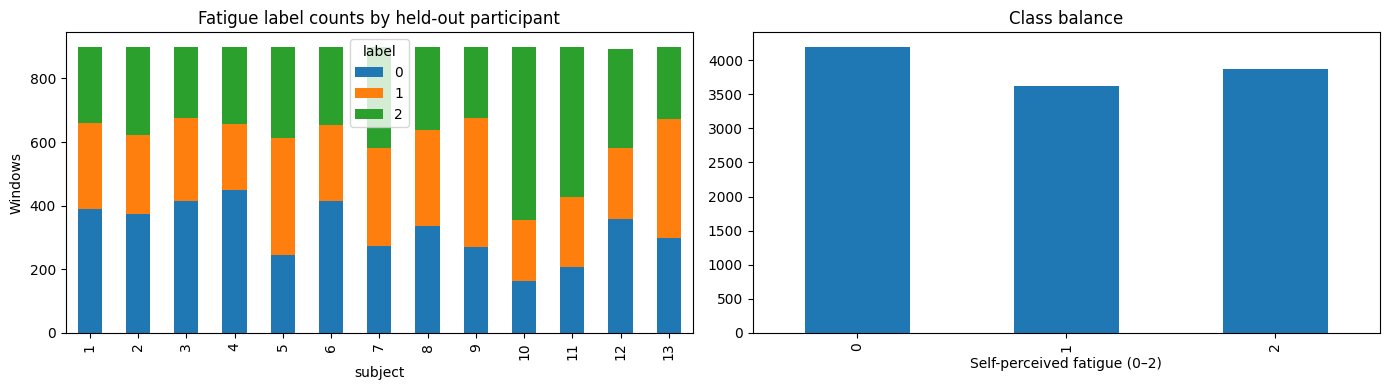

In [ ]:
import seaborn as sns
fig,axes=plt.subplots(1,2,figsize=(14,4))
META.groupby(['subject','label']).size().unstack(fill_value=0).plot.bar(stacked=True,ax=axes[0])
axes[0].set_title('Fatigue label counts by held-out participant');axes[0].set_ylabel('Windows')
META.label.value_counts().sort_index().plot.bar(ax=axes[1]);axes[1].set_title('Class balance');axes[1].set_xlabel('Self-perceived fatigue (0–2)')
plt.tight_layout();plt.savefig(OUT/'eda_label_balance.png',dpi=170);plt.show()

## 9. Classical model registry and evaluation metrics

The benchmark comprises a majority-class control, multinomial logistic regression, RBF SVM, random forest, histogram gradient boosting and a multilayer perceptron. Primary outcome is **mean subject-level macro-F1**, avoiding domination by participants with more windows. Auxiliary outcomes are subject-level balanced accuracy, precision, recall, weighted F1, train time and inference latency. Labels 0, 1 and 2 are retained explicitly in all evaluation functions.

In [ ]:
def model_registry():
    return {
      'majority':(DummyClassifier(strategy='most_frequent'),{}),
      'logistic':(Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('clf',LogisticRegression(max_iter=1200,class_weight='balanced',random_state=SEED))]),{'clf__C':[0.1,1.,10.]}),
      'svm_rbf':(Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('clf',SVC(class_weight='balanced',random_state=SEED))]),{'clf__C':[0.3,3.]}),
      'random_forest':(Pipeline([('impute',SimpleImputer(strategy='median')),('clf',RandomForestClassifier(n_estimators=130,class_weight='balanced_subsample',n_jobs=-1,random_state=SEED))]),{'clf__max_depth':[10,None]}),
      'hist_gradient_boosting':(Pipeline([('impute',SimpleImputer(strategy='median')),('clf',HistGradientBoostingClassifier(max_iter=100,random_state=SEED))]),{'clf__learning_rate':[0.05,0.15]}),
      'mlp':(Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('clf',MLPClassifier(hidden_layer_sizes=(96,48),early_stopping=True,max_iter=130,random_state=SEED))]),{'clf__alpha':[.001,.01]})
    }

def score_set(actual,pred):
    return dict(accuracy=accuracy_score(actual,pred),balanced_accuracy=balanced_accuracy_score(actual,pred),
                macro_f1=f1_score(actual,pred,labels=[0,1,2],average='macro',zero_division=0),
                weighted_f1=f1_score(actual,pred,labels=[0,1,2],average='weighted',zero_division=0),
                macro_precision=precision_score(actual,pred,labels=[0,1,2],average='macro',zero_division=0),
                macro_recall=recall_score(actual,pred,labels=[0,1,2],average='macro',zero_division=0))

## 10. Participant-held-out nested cross-validation for traditional models

The outer Leave-One-Subject-Out loop reserves every test subject until final evaluation. Hyperparameters are selected using GroupKFold over *training subjects only*. Scaling and imputation are refitted within inner folds. Every held-out prediction, selected parameter set, fit duration and inference latency is exported; fold checkpoints can be audited separately. Results are not tuned using target-subject outcomes.

In [ ]:
subjects=META.subject.to_numpy();registry=model_registry()
fold_rows=[]; prediction_rows=[];hyper_rows=[]
for k,(train,test) in enumerate(LeaveOneGroupOut().split(X,Y,subjects)):
    held=int(subjects[test[0]])
    if FAST_DEMO and k>=4:break
    unique=np.unique(subjects[train]);splits=min(3,len(unique))
    for name,(base,grid) in registry.items():
        saved=OUT/f'fold_{held:02d}_{name}.joblib'
        if saved.exists():
            result=joblib.load(saved)
        else:
            begin=time.perf_counter()
            if grid:
                search=GridSearchCV(clone(base),grid,scoring='f1_macro',cv=GroupKFold(n_splits=splits),n_jobs=1,error_score='raise')
                search.fit(X[train],Y[train],groups=subjects[train]); fitted=search.best_estimator_
                chosen=search.best_params_;inner_score=float(search.best_score_)
            else:
                fitted=clone(base).fit(X[train],Y[train]);chosen={};inner_score=None
            training_seconds=time.perf_counter()-begin
            begin=time.perf_counter();pred=fitted.predict(X[test]);inference_ms=1000*(time.perf_counter()-begin)/len(test)
            result={'held':held,'test_indices':test,'pred':pred,'best_params':chosen,'inner_cv':inner_score,'fit_s':training_seconds,'ms_window':inference_ms}
            joblib.dump(result,saved,compress=3)
        pred=result['pred']
        fold_rows.append(dict(subject=held,model=name,n_train=len(train),n_test=len(test),training_seconds=result['fit_s'],ms_per_window=result['ms_window'],inner_cv_macro_f1=result['inner_cv'],**score_set(Y[test],pred)))
        hyper_rows.append(dict(subject=held,model=name,best_params=json.dumps(result['best_params'])))
        prediction_rows += [dict(subject=held,model=name,window_id=int(idx),trial=int(META.iloc[idx].trial),time_s=float(META.iloc[idx].time_s),true=int(Y[idx]),pred=int(p)) for idx,p in zip(test,pred)]
    pd.DataFrame(fold_rows).to_csv(OUT/'nested_fold_scores.csv',index=False)
    pd.DataFrame(prediction_rows).to_csv(OUT/'nested_predictions.csv',index=False)
    pd.DataFrame(hyper_rows).to_csv(OUT/'nested_hyperparameters.csv',index=False)
    print(f'Completed participant {held}; checkpointed locally in Colab',flush=True)
FOLDS=pd.DataFrame(fold_rows);PRED=pd.DataFrame(prediction_rows)
SUMMARY=FOLDS.groupby('model',as_index=False).agg(mean_subject_macro_f1=('macro_f1','mean'),sd_subject_macro_f1=('macro_f1','std'),mean_balanced_accuracy=('balanced_accuracy','mean'),mean_precision=('macro_precision','mean'),mean_recall=('macro_recall','mean'),mean_ms_per_window=('ms_per_window','mean'),tested_subjects=('subject','nunique')).sort_values('mean_subject_macro_f1',ascending=False)
SUMMARY.to_csv(OUT/'nested_model_summary.csv',index=False)
display(SUMMARY)

Completed participant 1; checkpointed locally in Colab
Completed participant 2; checkpointed locally in Colab
Completed participant 3; checkpointed locally in Colab
Completed participant 4; checkpointed locally in Colab
Completed participant 5; checkpointed locally in Colab
Completed participant 6; checkpointed locally in Colab
Completed participant 7; checkpointed locally in Colab
Completed participant 8; checkpointed locally in Colab
Completed participant 9; checkpointed locally in Colab
Completed participant 10; checkpointed locally in Colab
Completed participant 11; checkpointed locally in Colab
Completed participant 12; checkpointed locally in Colab
Completed participant 13; checkpointed locally in Colab


,model,mean_subject_macro_f1,sd_subject_macro_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_ms_per_window,tested_subjects
0,hist_gradient_boosting,0.435359,0.036848,0.462716,0.466177,0.462716,0.026469,13
3,mlp,0.434387,0.042166,0.460965,0.467245,0.460965,0.003644,13
5,svm_rbf,0.430112,0.052423,0.454369,0.473904,0.454369,0.927439,13
4,random_forest,0.422562,0.063283,0.455518,0.471834,0.455518,0.065023,13
1,logistic,0.417315,0.053078,0.451532,0.463216,0.451532,0.003634,13
2,majority,0.173742,0.036306,0.333333,0.119693,0.333333,0.000236,13


## 11. Pre-registered supervised personalization design

A separate, **supervised** domain-adaptation experiment compares a source-only classifier trained on other participants against one retrained with **labeled** early windows of the new subject's trial. Only later windows, following a 2-second embargo, constitute query samples. Support labels are not included among query predictions. This experiment assesses the benefit of calibration; it is **not** unsupervised fatigue adaptation and must not be compared uncritically with the strictly zero-shot LOSO benchmark.

In [ ]:
ADAPT_BASE='logistic'
# Fixed hyperparameter; do not choose based on test-subject predictions.
fixed_model=registry[ADAPT_BASE][0]
adapt_results=[];adapt_preds=[];adapt_excluded=[]
for subject in sorted(META.subject.unique()):
    if FAST_DEMO and subject not in sorted(META.subject.unique())[:4]:break
    tr=np.flatnonzero(subjects!=subject)
    if len(np.unique(Y[tr]))<2:continue
    source=clone(fixed_model).fit(X[tr],Y[tr])
    target_meta=META.loc[META.subject==subject]
    for trial in sorted(target_meta.trial.unique()):
        inds=target_meta.index[target_meta.trial==trial].to_numpy()
        inds=inds[np.argsort(META.iloc[inds].time_s.to_numpy())]
        tm=META.iloc[inds].time_s.to_numpy()
        split=int(np.floor(len(inds)*SUPPORT_FRACTION))
        if split<8 or len(inds)-split<8:
            adapt_excluded.append(dict(subject=subject,trial=trial,reason='insufficient support/query'));continue
        support=inds[:split];query=inds[tm > tm[split-1]+GAP_SECONDS]
        if len(query)<8:
            adapt_excluded.append(dict(subject=subject,trial=trial,reason='embargo removed query'));continue
        calibrated=clone(fixed_model).fit(np.concatenate([X[tr],X[support]]),np.concatenate([Y[tr],Y[support]]))
        for variant,yp in [('source_only',source.predict(X[query])),('supervised_support',calibrated.predict(X[query]))]:
            adapt_results.append(dict(subject=subject,trial=trial,variant=variant,n_support=len(support),n_query=len(query),**score_set(Y[query],yp)))
            adapt_preds.extend(dict(subject=subject,trial=trial,variant=variant,window_id=int(idx),true=int(Y[idx]),pred=int(val)) for idx,val in zip(query,yp))
    pd.DataFrame(adapt_results).to_csv(OUT/'adaptation_trial_scores.csv',index=False)
    pd.DataFrame(adapt_preds).to_csv(OUT/'adaptation_predictions.csv',index=False)
ADAPT=pd.DataFrame(adapt_results)
pd.DataFrame(adapt_excluded,columns=['subject','trial','reason']).to_csv(OUT/'adaptation_excluded_trials.csv',index=False)
if not ADAPT.empty:
    ADAPT.groupby('variant')[['macro_f1','balanced_accuracy']].mean().to_csv(OUT/'adaptation_summary.csv')
    display(ADAPT.groupby('variant')[['macro_f1','balanced_accuracy']].agg(['mean','std','count']))
else: print('No eligible adaptation trials: inspect exclusions; do not claim adaptation gains.')

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

macro_f1                 balanced_accuracy                
                        mean       std count              mean       std count
variant                                                                       
source_only         0.312133  0.122589   105          0.404950  0.120812   105
supervised_support  0.310364  0.121308   105          0.405213  0.118505   105

## 12. Full subject-independent 1D convolutional architectures

Two deep architectures are compared under the **same 13 outer LOSO subject splits** as traditional models: a compact 1D-CNN and a convolutional recurrent CNN-GRU. For each outer fold, one **training-only** participant is selected for validation (fixed deterministic group assignment), while the other training participants fit network weights. Network normalization, class weights, model choice and early stopping never inspect held-out test data. Model checkpoints are saved for every subject and architecture.

Deep-learning model selection uses a prespecified fixed search budget and training-only group validation, not target-participant labels. Because neural and classical search budgets differ, results are compared on held-out outcomes while documenting those differences. CPU runs may take substantially longer than GPU runs.

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
try:
    torch.set_num_threads(min(4,os.cpu_count() or 2))
except Exception:
    pass
torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)

class TemporalCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv1d(4,24,7,padding=3),nn.BatchNorm1d(24),nn.ReLU(),
            nn.MaxPool1d(2),nn.Conv1d(24,48,5,padding=2),nn.BatchNorm1d(48),nn.ReLU(),
            nn.MaxPool1d(2),nn.Conv1d(48,64,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool1d(1))
        self.head=nn.Linear(64,3)
    def forward(self,x):return self.head(self.features(x).squeeze(-1))

class CNNGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv=nn.Sequential(nn.Conv1d(4,24,7,padding=3),nn.BatchNorm1d(24),nn.ReLU(),
            nn.MaxPool1d(2),nn.Conv1d(24,40,5,padding=2),nn.BatchNorm1d(40),nn.ReLU(),nn.MaxPool1d(2))
        self.gru=nn.GRU(input_size=40,hidden_size=48,batch_first=True,bidirectional=True)
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(96,3))
    def forward(self,x):
        z=self.conv(x).transpose(1,2)
        z,_=self.gru(z)
        return self.head(z.mean(dim=1))

DEEP_ARCHS={'cnn_1d':TemporalCNN,'cnn_gru':CNNGRU}
print('Compute device:',DEVICE)

Compute device: cpu


## 13. Neural training, validation and checkpoint functions

Deep models use training-only per-channel standardization, class-weighted cross-entropy, AdamW, gradient clipping and early stopping based on training-subject validation macro-F1. Input to both networks has shape *(windows, four muscle channels, 256 time bins)*. Every fold stores its training trace and selected epoch. Checkpoints include fitted normalization parameters to support reproduction.

In [ ]:
def deep_normalization(train_idx):
    # Per-channel statistics only from nonvalidation training participants.
    z=RAW_WINDOWS[train_idx]
    mu=z.mean(axis=(0,2),keepdims=True)
    sd=np.maximum(z.std(axis=(0,2),keepdims=True),1e-7)
    return mu.astype(np.float32),sd.astype(np.float32)

def load_deep_data(indices,mu,sd):
    a=np.clip((RAW_WINDOWS[indices]-mu)/sd,-8,8).astype(np.float32)
    return TensorDataset(torch.from_numpy(a),torch.from_numpy(Y[indices].astype(np.int64)))

def infer_deep(model,indices,mu,sd):
    loader=DataLoader(load_deep_data(indices,mu,sd),batch_size=256,shuffle=False)
    model.eval();pred=[]
    with torch.no_grad():
        for xb,_ in loader:
            logits=model(xb.to(DEVICE));pred.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(pred) if pred else np.array([],dtype=int)

def train_deep_fold(architecture,held,train_idx,test_idx):
    checkpoint=OUT/f'deep_{architecture}_subject_{held:02d}.pt'
    predfile=OUT/f'deep_{architecture}_subject_{held:02d}_pred.csv'
    infofile=OUT/f'deep_{architecture}_subject_{held:02d}.json'
    if checkpoint.exists() and predfile.exists() and infofile.exists():
        return json.loads(infofile.read_text()),pd.read_csv(predfile)
    groups=np.unique(subjects[train_idx])
    val_subject=int(groups[(held+SEED)%len(groups)])
    fit_idx=train_idx[subjects[train_idx]!=val_subject]
    val_idx=train_idx[subjects[train_idx]==val_subject]
    if len(np.unique(Y[fit_idx]))<2:raise ValueError('Insufficient classes in deep fold training partition')
    mu,sd=deep_normalization(fit_idx)
    train_loader=DataLoader(load_deep_data(fit_idx,mu,sd),batch_size=CNN_BATCH_SIZE,shuffle=True)
    model=DEEP_ARCHS[architecture]().to(DEVICE)
    weights=np.bincount(Y[fit_idx],minlength=3).astype(float)
    weights=weights.sum()/np.maximum(weights,1)
    loss_fn=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
    optim=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-3)
    best=-1.0;wait=0;beststate=None;bestepoch=0;trace=[]
    started=time.perf_counter()
    for epoch in range(CNN_EPOCHS):
        model.train();trainloss=0.0
        for xb,yb in train_loader:
            optim.zero_grad(set_to_none=True)
            logits=model(xb.to(DEVICE));loss=loss_fn(logits,yb.to(DEVICE))
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.0);optim.step()
            trainloss+=float(loss.item())
        valpred=infer_deep(model,val_idx,mu,sd)
        valf=f1_score(Y[val_idx],valpred,labels=[0,1,2],average='macro',zero_division=0)
        trace.append({'subject':held,'model':architecture,'epoch':epoch+1,'loss':trainloss/max(len(train_loader),1),'val_macro_f1':valf})
        if valf>best+1e-4:
            best=valf;wait=0;bestepoch=epoch+1
            beststate={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait+=1
            if wait>=CNN_PATIENCE:break
    model.load_state_dict(beststate);model=model.to(DEVICE)
    startpred=time.perf_counter();p=infer_deep(model,test_idx,mu,sd)
    latency=1000*(time.perf_counter()-startpred)/max(1,len(test_idx))
    pd.DataFrame(trace).to_csv(OUT/f'deep_{architecture}_subject_{held:02d}_learning_curve.csv',index=False)
    torch.save({'model':beststate,'train_mean':mu,'train_sd':sd,'val_subject':val_subject,'best_epoch':bestepoch,'architecture':architecture},checkpoint)
    preds=pd.DataFrame({'subject':held,'model':architecture,'window_id':test_idx,'trial':META.iloc[test_idx].trial.to_numpy(),'time_s':META.iloc[test_idx].time_s.to_numpy(),'true':Y[test_idx],'pred':p})
    preds.to_csv(predfile,index=False)
    info={'subject':held,'model':architecture,'val_subject':val_subject,'best_epoch':bestepoch,
          'validation_macro_f1':best,'n_train':len(fit_idx),'n_val':len(val_idx),'n_test':len(test_idx),
          'training_seconds':time.perf_counter()-started,'ms_per_window':latency,**score_set(Y[test_idx],p)}
    infofile.write_text(json.dumps(info,indent=2))
    return info,preds

## 14. Full LOSO convolutional benchmarking

Every participant is held out in turn. The two deep architectures are trained separately on the remaining participants, with validation drawn from a single **other** participant. Evaluation uses the identical participant-wise targets as classical models. The outputs include per-participant scores, detailed predictions, learning curves and final checkpoints; incomplete folds are explicitly logged rather than hidden.

In [ ]:
DEEP_ROWS=[];DEEP_PRED=[];DEEP_ERRORS=[]
if CNN_ENABLED:
    for train_idx,test_idx in LeaveOneGroupOut().split(X,Y,subjects):
        held=int(subjects[test_idx[0]])
        for arch in DEEP_ARCHS:
            try:
                result,preds=train_deep_fold(arch,held,train_idx,test_idx)
                DEEP_ROWS.append(result);DEEP_PRED.append(preds)
                print(f'Deep holdout subject={held}, model={arch}, macro-F1={result["macro_f1"]:.3f}',flush=True)
            except Exception as e:
                DEEP_ERRORS.append({'subject':held,'model':arch,'error':str(e)})
                print('Deep fold failure:',held,arch,type(e).__name__,str(e),flush=True)
        pd.DataFrame(DEEP_ROWS).to_csv(OUT/'deep_fold_scores.csv',index=False)
        if DEEP_PRED:pd.concat(DEEP_PRED,ignore_index=True).to_csv(OUT/'deep_predictions.csv',index=False)
        pd.DataFrame(DEEP_ERRORS,columns=['subject','model','error']).to_csv(OUT/'deep_fold_errors.csv',index=False)
DEEP_FOLDS=pd.DataFrame(DEEP_ROWS)
if CNN_ENABLED and (len(DEEP_FOLDS)<len(np.unique(subjects))*len(DEEP_ARCHS)):
    raise RuntimeError('Deep subject-held-out evaluation incomplete; see deep_fold_errors.csv. Scientific results cannot be finalized.')
if not DEEP_FOLDS.empty:display(DEEP_FOLDS.groupby('model')['macro_f1'].agg(['mean','std','count']))

Deep holdout subject=1, model=cnn_1d, macro-F1=0.363
Deep holdout subject=1, model=cnn_gru, macro-F1=0.433
Deep holdout subject=2, model=cnn_1d, macro-F1=0.294
Deep holdout subject=2, model=cnn_gru, macro-F1=0.291
Deep holdout subject=3, model=cnn_1d, macro-F1=0.367
Deep holdout subject=3, model=cnn_gru, macro-F1=0.314
Deep holdout subject=4, model=cnn_1d, macro-F1=0.508
Deep holdout subject=4, model=cnn_gru, macro-F1=0.433
Deep holdout subject=5, model=cnn_1d, macro-F1=0.398
Deep holdout subject=5, model=cnn_gru, macro-F1=0.311
Deep holdout subject=6, model=cnn_1d, macro-F1=0.436
Deep holdout subject=6, model=cnn_gru, macro-F1=0.390
Deep holdout subject=7, model=cnn_1d, macro-F1=0.257
Deep holdout subject=7, model=cnn_gru, macro-F1=0.245
Deep holdout subject=8, model=cnn_1d, macro-F1=0.387
Deep holdout subject=8, model=cnn_gru, macro-F1=0.421
Deep holdout subject=9, model=cnn_1d, macro-F1=0.262
Deep holdout subject=9, model=cnn_gru, macro-F1=0.357
Deep holdout subject=10, model=cnn_1d

,mean,std,count
model,,,
cnn_1d,0.369303,0.075396,13
cnn_gru,0.356895,0.065429,13


## 15. Full model comparison under aligned test participants

Classical and deep results are aligned by outer held-out subject. Each method is compared on the same subject set and test-window labels, but different validation strategies and compute budgets are transparently recorded. The table emphasizes subject-averaged macro-F1 and between-subject standard deviation, rather than an inflated pooled-window metric.

In [ ]:
ALL_FOLDS=pd.concat([FOLDS,DEEP_FOLDS],ignore_index=True,sort=False)
ALL_SUMMARY=ALL_FOLDS.groupby('model',as_index=False).agg(mean_subject_macro_f1=('macro_f1','mean'),sd_subject_macro_f1=('macro_f1','std'),
      mean_balanced_accuracy=('balanced_accuracy','mean'),mean_precision=('macro_precision','mean'),
      mean_recall=('macro_recall','mean'),mean_ms_per_window=('ms_per_window','mean'),tested_subjects=('subject','nunique')).sort_values('mean_subject_macro_f1',ascending=False)
assert ALL_SUMMARY.tested_subjects.eq(META.subject.nunique()).all(),'One or more models lack complete held-out subject coverage'
ALL_FOLDS.to_csv(OUT/'all_model_fold_scores.csv',index=False)
ALL_SUMMARY.to_csv(OUT/'all_model_summary.csv',index=False)
ALL_PRED=pd.concat([PRED]+DEEP_PRED,ignore_index=True)
ALL_PRED.to_csv(OUT/'all_model_predictions.csv',index=False)
display(ALL_SUMMARY)

,model,mean_subject_macro_f1,sd_subject_macro_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_ms_per_window,tested_subjects
2,hist_gradient_boosting,0.435359,0.036848,0.462716,0.466177,0.462716,0.026469,13
5,mlp,0.434387,0.042166,0.460965,0.467245,0.460965,0.003644,13
7,svm_rbf,0.430112,0.052423,0.454369,0.473904,0.454369,0.927439,13
6,random_forest,0.422562,0.063283,0.455518,0.471834,0.455518,0.065023,13
3,logistic,0.417315,0.053078,0.451532,0.463216,0.451532,0.003634,13
0,cnn_1d,0.369303,0.075396,0.411032,0.412632,0.411032,0.120402,13
1,cnn_gru,0.356895,0.065429,0.392583,0.421427,0.392583,0.448915,13
4,majority,0.173742,0.036306,0.333333,0.119693,0.333333,0.000236,13


## 16. Feature-domain ablation studies

A fixed logistic-regression baseline is trained and tested under Leave-One-Subject-Out partitions using either time-domain features only, frequency-domain features only, or all features. All variants use equal participant splits and the same fixed model configuration. These are controlled feature-family ablations rather than a retuned search per subset.

In [ ]:
A_NAMES=['MAV','RMS','STD','WL','ZC','SSC','WAMP','LOGVAR','MNF','MDF','SPENT']
time_ix=np.array([j*11+i for j in range(4) for i in range(8)])
freq_ix=np.array([j*11+i for j in range(4) for i in range(8,11)])
ABL=[]
for variant,cols in [('time_only',time_ix),('frequency_only',freq_ix),('all_features',np.arange(X.shape[1]))]:
    for train,test in LeaveOneGroupOut().split(X,Y,subjects):
        if FAST_DEMO and len(ABL)>=4*3:break
        m=clone(fixed_model).fit(X[train][:,cols],Y[train])
        p=m.predict(X[test][:,cols])
        ABL.append(dict(subject=int(subjects[test[0]]),variant=variant,**score_set(Y[test],p)))
ABL=pd.DataFrame(ABL)
ABL.to_csv(OUT/'ablation_scores.csv',index=False)
if not ABL.empty:display(ABL.groupby('variant')['macro_f1'].agg(['mean','std','count']))

,mean,std,count
variant,,,
all_features,0.418628,0.051176,13
frequency_only,0.350880,0.090511,13
time_only,0.415357,0.057118,13


## 17. Participant-level uncertainty and error characterization

Bootstrap confidence intervals resample held-out **subjects**, not overlapping windows. Confusion matrices pool the out-of-subject predictions with the class order [0,1,2], and include both counts and normalized rates. Per-fatigue-class precision, recall and F1 are recorded for each model. Statistical results are exploratory because only 13 participant clusters are available.

In [ ]:
# Cluster-level bootstrap: subject is the unit of resampling.
def bootstrap_subject_ci(values,replicates=3000,seed=SEED):
    rng=np.random.default_rng(seed);a=np.asarray(values,float)
    if not len(a):return np.nan,np.nan
    means=np.mean(rng.choice(a,size=(replicates,len(a)),replace=True),axis=1)
    return np.percentile(means,[2.5,97.5])
ci=[]
for model,g in ALL_FOLDS.groupby('model'):
    low,high=bootstrap_subject_ci(g.macro_f1)
    ci.append({'model':model,'ci95_lower':low,'ci95_upper':high})
pd.DataFrame(ci).to_csv(OUT/'subject_bootstrap_ci.csv',index=False)

import seaborn as sns
classification=[]
for name,g in ALL_PRED.groupby('model'):
    cm=confusion_matrix(g.true,g.pred,labels=[0,1,2])
    pd.DataFrame(cm,index=['true_0','true_1','true_2'],columns=['pred_0','pred_1','pred_2']).to_csv(OUT/f'confusion_{name}.csv')
    norm=cm/(cm.sum(axis=1,keepdims=True)+1e-12)
    pd.DataFrame(norm).to_csv(OUT/f'confusion_normalized_{name}.csv',index=False)
    fig,ax=plt.subplots(figsize=(5,4))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=ax)
    ax.set_title(f'{name}: held-out subjects');ax.set_xlabel('Predicted fatigue class');ax.set_ylabel('True fatigue class')
    fig.tight_layout();fig.savefig(OUT/f'confusion_{name}.png',dpi=170);plt.close(fig)
    report=classification_report(g.true,g.pred,labels=[0,1,2],output_dict=True,zero_division=0)
    for target in ('0','1','2'):
        classification.append({'model':name,'class':int(target),**report[target]})
pd.DataFrame(classification).to_csv(OUT/'per_class_metrics.csv',index=False)

## 18. Statistical paired comparisons and adaptation effect

Paired differences use participants common to the two tested systems. For subject-level paired classification, the zero-shot performance of the strongest **classical** method is compared with the best-performing deep architecture descriptively; statistical tests are exploratory and require caution regarding model selection after observing the same subjects. For calibration, source-only and calibrated predictions are compared on identical later segments, and individual subject-level deltas are reported.

In [ ]:
# Descriptive subject-paired deltas only: winner selection has post-selection bias.
all_piv=ALL_FOLDS.pivot_table(index='subject',columns='model',values='macro_f1')
all_piv.to_csv(OUT/'subject_paired_model_scores.csv')
if not ADAPT.empty:
    pair=ADAPT.pivot_table(index=['subject','trial'],columns='variant',values='macro_f1')
    if {'source_only','supervised_support'}.issubset(pair.columns):
        pair=pair.dropna().copy()
        pair['delta_macro_f1']=pair['supervised_support']-pair['source_only']
        pair.to_csv(OUT/'adaptation_trial_paired_deltas.csv')
        by_subject=pair.groupby(level=0)['delta_macro_f1'].mean()
        by_subject.to_csv(OUT/'adaptation_subject_mean_delta.csv')
        if len(by_subject)>4 and np.any(by_subject):
            from scipy.stats import wilcoxon
            try:
                statistic,pvalue=wilcoxon(by_subject.values,zero_method='wilcox')
                (OUT/'adaptation_exploratory_test.json').write_text(json.dumps({'method':'wilcoxon_subject_mean_paired_delta','n_subjects':len(by_subject),'p_unadjusted':float(pvalue)},indent=2))
            except ValueError:pass

## 19. Publication-oriented result figures

Plots are generated from saved participant-held-out predictions and scores. Cross-subject variability, confusion, trial-specific calibration and model performance are presented without invented claims. Figures use unaltered metric values; interpretation belongs to the research report after actual execution.

In [ ]:
fig,ax=plt.subplots(figsize=(11,6))
plot_data=ALL_SUMMARY.sort_values('mean_subject_macro_f1')
ax.barh(plot_data.model,plot_data.mean_subject_macro_f1,xerr=plot_data.sd_subject_macro_f1,capsize=3)
ax.set_xlim(0,1);ax.set_xlabel('Mean held-out subject macro-F1 ± subject SD')
ax.set_title('Participant-independent fatigue classification')
fig.tight_layout();fig.savefig(OUT/'all_model_comparison.png',dpi=200);plt.close(fig)
fig,ax=plt.subplots(figsize=(12,5))
sns.boxplot(data=ALL_FOLDS,x='model',y='macro_f1',ax=ax,color='lightgray')
sns.stripplot(data=ALL_FOLDS,x='model',y='macro_f1',ax=ax,color='black',size=3)
ax.set_ylim(0,1);ax.tick_params(axis='x',rotation=35);ax.set_title('Subject-level score distributions')
fig.tight_layout();fig.savefig(OUT/'subject_score_distributions.png',dpi=200);plt.close(fig)
if not ADAPT.empty:
    fig,ax=plt.subplots(figsize=(7,5))
    sns.boxplot(data=ADAPT,x='variant',y='macro_f1',ax=ax,color='lightgray')
    ax.set_ylim(0,1);ax.set_title('Source-only versus supervised calibration (trial-level)')
    fig.tight_layout();fig.savefig(OUT/'adaptation_comparison.png',dpi=200);plt.close(fig)

## 20. Reproducibility inventory, limitations and scientific handoff

The final ZIP stores the experimental configuration, environment, paired trial manifest, signal-schema audits, preprocessing exclusions, fold-level predictions, model comparisons, feature-domain ablations, calibration estimates, uncertainty analyses and figures. Neural checkpoints remain accessible in the Colab workspace, but are excluded from the compact report ZIP to avoid excessive download size.

**Limitations.** Ground truth is self-reported fatigue; class imbalance and trial/task confounding may limit generalization. Only participants in the source dataset are studied. Channel positions may correspond to different recorded muscles across right- versus left-arm trials; this creates potential movement/channel confounding. Window subsampling is explicitly documented. The adaptation stage uses labeled target data and cannot be described as autonomous unsupervised adaptation. Neural networks use a group-held-out early-stopping participant, while classical models use grouped inner hyperparameter search. Performance on held-out participants must not be mistaken for deployment validation or clinical diagnosis.

In [ ]:
from datetime import datetime, timezone
import zipfile
CONFIG={'dataset_url':'https://zenodo.org/records/14182446','seed':SEED,'n_subjects':int(META.subject.nunique()),
 'n_paired_trials':int(len(MANIFEST)),'n_windows':int(len(Y)),
 'window_seconds':WINDOW_SECONDS,'hop_seconds':HOP_SECONDS,'purity_threshold':PURITY_THRESHOLD,
 'max_label_age_s':MAX_LABEL_AGE_SECONDS,'max_windows_subject':MAX_WINDOWS_PER_SUBJECT,
 'max_windows_trial':MAX_WINDOWS_PER_TRIAL,'classes':[0,1,2],'CNN_EPOCHS':CNN_EPOCHS,
 'CNN_PATIENCE':CNN_PATIENCE,'CNN_BATCH_SIZE':CNN_BATCH_SIZE,'compute_device':str(DEVICE),
 'support_fraction':SUPPORT_FRACTION,'gap_seconds':GAP_SECONDS,'execution_utc':datetime.now(timezone.utc).isoformat(),
 'raw_data_not_included_in_result_archive':True,'subject_independent_evaluation':True,
 'limitations':['Self-perceived fatigue ratings','Overlapping windows','Finite per-subject sampling','Only dataset participants','Offline zero-phase filtering']}
(OUT/'experiment_configuration.json').write_text(json.dumps(CONFIG,indent=2))
report=['# Executed Results and Methods Audit','',
        f'Participants evaluated: {META.subject.nunique()}',f'Matched recordings: {len(MANIFEST)}',
        f'Labeled windows: {len(Y)}','',
        '## Held-out participant model summary',ALL_SUMMARY.to_markdown(index=False),
        '','## Important interpretation','Target labels are ordinal self-perceived fatigue assessments.',
        'The calibration study uses labeled target-participant support observations.',
        'Outer held-out participants are disjoint from all training subjects.']
(OUT/'EXECUTED_RESEARCH_SUMMARY.md').write_text('\n'.join(report))
PACKAGE=Path('/content/EMG_SEND_RESULTS_FOR_REPORT.zip')
with zipfile.ZipFile(PACKAGE,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and p.suffix.lower() not in ('.joblib','.pt'):
            z.write(p,arcname='results/'+p.relative_to(OUT).as_posix())
print('Export:',PACKAGE,'MB:',round(PACKAGE.stat().st_size/1e6,2))
try:
    from google.colab import files
    files.download(str(PACKAGE))
except ImportError:
    print('Results ZIP saved locally:',PACKAGE)

Export: /content/EMG_SEND_RESULTS_FOR_REPORT.zip MB: 2.64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References and reproducibility statement

- Cerqueira, S., Vilas-Boas, R., Figueiredo, J., & Santos, C. (2024). *A Dataset of sEMG and Self-Perceived Fatigue Levels for Muscle Fatigue Analysis* (Version 2) [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.14182446
- Hudgins, B., Parker, P., & Scott, R. N. (1993). A new strategy for multifunction myoelectric control. *IEEE Transactions on Biomedical Engineering*, 40(1), 82–94. https://doi.org/10.1109/10.204774
- Phinyomark, A., Phukpattaranont, P., & Limsakul, C. (2012). Feature reduction and selection for EMG signal classification. *Expert Systems with Applications*, 39(8), 7420–7431. https://doi.org/10.1016/j.eswa.2012.01.102
- Leave-One-Group-Out and grouped validation: [scikit-learn documentation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).

**Reporting standard.** Include numeric results only after running all authentic participant folds. Do not present synthetic or partial-run values as final study outcomes. A substantive scholarly literature review and interpretation of results should be finalized using the archived experiment outputs and verified references.